In [142]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

In [143]:
data = pd.read_csv('./datasets/AAPL.csv')
data.head(100)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1980-12-12 00:00:00-05:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0
1,1980-12-15 00:00:00-05:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0
2,1980-12-16 00:00:00-05:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0
3,1980-12-17 00:00:00-05:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0
4,1980-12-18 00:00:00-05:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0
...,...,...,...,...,...,...,...,...
95,1981-04-30 00:00:00-04:00,0.097545,0.098405,0.097545,0.097545,12611200,0.0,0.0
96,1981-05-01 00:00:00-04:00,0.097545,0.098405,0.097545,0.097545,16553600,0.0,0.0
97,1981-05-04 00:00:00-04:00,0.097545,0.097545,0.097116,0.097116,14448000,0.0,0.0
98,1981-05-05 00:00:00-04:00,0.097116,0.097116,0.096686,0.096686,17539200,0.0,0.0


In [144]:
data.dtypes

Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

In [145]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11082 entries, 0 to 11081
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          11082 non-null  object 
 1   Open          11082 non-null  float64
 2   High          11082 non-null  float64
 3   Low           11082 non-null  float64
 4   Close         11082 non-null  float64
 5   Volume        11082 non-null  int64  
 6   Dividends     11082 non-null  float64
 7   Stock Splits  11082 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 692.8+ KB


Remove every entry before 2004

In [146]:
data = data[data['Date'] >= '2004-01-01']

In [147]:
data['Date'] = pd.to_datetime(data['Date'], utc=True)

data['Quarter'] = data['Date'].dt.quarter




Calculating Features about data 

In [148]:
data['week_number'] = data['Date'].dt.isocalendar().week
data['week_day'] = data['Date'].dt.weekday
data['month']  = data['Date'].dt.month


Add inflation values 

(the inflation api only has values for the first day of each year, so it is being applied the same value for each day of that year)

In [149]:
import os
api_key = os.getenv('ALPHA_VANTAGE_API_KEY')

url = f'https://www.alphavantage.co/query?function=INFLATION&apikey={api_key}'
r = requests.get(url)
data_inflation = r.json()

# Create a mapping of inflation values by year
inflation_mapping = {item['date'][:4]: float(item['value']) for item in data_inflation['data']}
# Add inflation value for 2024
inflation_mapping['2024'] = 2.6

# Add a new column for Inflation to the dataset
data['Inflation'] = None

# Apply the inflation value for each row based on the year
for index, row in data.iterrows():
    year = row['Date'].year
    if str(year) in inflation_mapping:
        data.at[index, 'Inflation'] = inflation_mapping[str(year)]

# Ensure 'Inflation' column is numeric
data['Inflation'] = pd.to_numeric(data['Inflation'], errors='coerce')

# Check for NaNs in the column after conversion
if data['Inflation'].isnull().any():
    print("Found NaNs in 'Inflation' column after conversion. Filling with a default value (e.g., median).")
    data['Inflation'].fillna(data['Inflation'].median(), inplace=True)

# Drop any remaining NaN rows (optional)
data.dropna(inplace=True)


print(data[['Date', 'Inflation']])

                           Date  Inflation
5820  2004-01-02 05:00:00+00:00   2.677237
5821  2004-01-05 05:00:00+00:00   2.677237
5822  2004-01-06 05:00:00+00:00   2.677237
5823  2004-01-07 05:00:00+00:00   2.677237
5824  2004-01-08 05:00:00+00:00   2.677237
...                         ...        ...
11077 2024-11-20 05:00:00+00:00   2.600000
11078 2024-11-21 05:00:00+00:00   2.600000
11079 2024-11-22 05:00:00+00:00   2.600000
11080 2024-11-25 05:00:00+00:00   2.600000
11081 2024-11-26 05:00:00+00:00   2.600000

[5262 rows x 2 columns]


Addition of CPI (Consumer Price Index) data 

- The CPI is retrieved monthly

In [150]:
url = f'https://www.alphavantage.co/query?function=CPI&interval=monthly&apikey={api_key}'
r = requests.get(url)
cpi_data = r.json()

# Extract CPI values
cpi_monthly = cpi_data.get('data', [])

# Create a mapping from Year-Month to CPI value
cpi_mapping = {
    entry['date'][:7]: float(entry['value'])  # Extract Year-Month from the "date" field
    for entry in cpi_monthly
}

data['YearMonth'] = data['Date'].dt.strftime('%Y-%m')  # Extract Year-Month as a string

# Add CPI column to the dataset
data['CPI'] = data['YearMonth'].map(cpi_mapping)  # Map the CPI values

data.drop(columns=['YearMonth'], inplace=True)

data.head()



,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Quarter,week_number,week_day,month,Inflation,CPI
5820,2004-01-02 05:00:00+00:00,0.324615,0.327628,0.319041,0.320548,144642400,0.0,0.0,1,1,4,1,2.677237,185.2
5821,2004-01-05 05:00:00+00:00,0.322657,0.337268,0.322657,0.333955,395018400,0.0,0.0,1,2,0,1,2.677237,185.2
5822,2004-01-06 05:00:00+00:00,0.335159,0.337720,0.327026,0.332749,509348000,0.0,0.0,1,2,1,1,2.677237,185.2
5823,2004-01-07 05:00:00+00:00,0.332900,0.343896,0.330339,0.340281,586874400,0.0,0.0,1,2,2,1,2.677237,185.2
5824,2004-01-08 05:00:00+00:00,0.344047,0.357453,0.341185,0.351880,460303200,0.0,0.0,1,2,3,1,2.677237,185.2


calculating features on price 

In [151]:
#### Price Based Features #####

# Daily Range
data["Daily Range"] = data["High"] - data["Low"]

# 3. Direction
data["Direction"] = (data["Close"] > data["Open"]).astype(int)

# 4. Percentage Change
data["Percentage Change"] = ((data["Close"] - data["Open"]) / data["Open"]) * 100

# 6. Momentum (10-day)
data["Momentum_10"] = data["Close"] - data["Close"].shift(10)


# ===================== TREND AND MOVING AVERAGES =====================

# Simple Moving Average (SMA)
data["SMA_5"] = data["Close"].rolling(window=5).mean()
data["SMA_20"] = data["Close"].rolling(window=20).mean()


# ===================== VOLATILITY FEATURES =====================

# Rolling Standard Deviation (Volatility)
data["5-Day Volatility"] = data["Close"].rolling(window=5).std()

# ===================== MOMENTUM AND OSCILLATORS =====================

# Relative Strength Index (RSI)
data['Change'] = data['Close'] - data['Close'].shift(1)
data['Gain'] = data['Change'].where(data['Change'] > 0, 0)
data['Loss'] = -data['Change'].where(data['Change'] < 0, 0)
data['Avg_Gain'] = data['Gain'].rolling(window=14).mean()
data['Avg_Loss'] = data['Loss'].rolling(window=14).mean()
data['RS'] = data['Avg_Gain'] / data['Avg_Loss']
data['RSI'] = 100 - (100 / (1 + data['RS']))

# ===================== VOLUME-BASED FEATURES =====================

# Volume Moving Average
data['Volume_SMA_10'] = data['Volume'].rolling(window=10).mean()

# Volume Change (Percentage)
data['Volume Change'] = data['Volume'].pct_change() * 100

# On-Balance Volume (OBV)
data['OBV'] = (data['Volume'] * ((data['Close'] > data['Close'].shift(1)).astype(int) - (data['Close'] < data['Close'].shift(1)).astype(int))).cumsum()

# ===================== RETURN-BASED FEATURES =====================

# Daily Return
data['Daily Return'] = data['Close'].pct_change()

# 2. Calculate returns over different periods
data['7-Day Return'] = (data['Close'] / data['Close'].shift(7) - 1) * 100  # 7 days
data['1-Month Return'] = (data['Close'] / data['Close'].shift(30) - 1) * 100  # 30 days
data['6-Month Return'] = (data['Close'] / data['Close'].shift(182) - 1) * 100  # ~6 months
data['1-Year Return'] = (data['Close'] / data['Close'].shift(365) - 1) * 100  # 1 year


Mean Squared Error: 3.2429
R-Squared: 0.9992


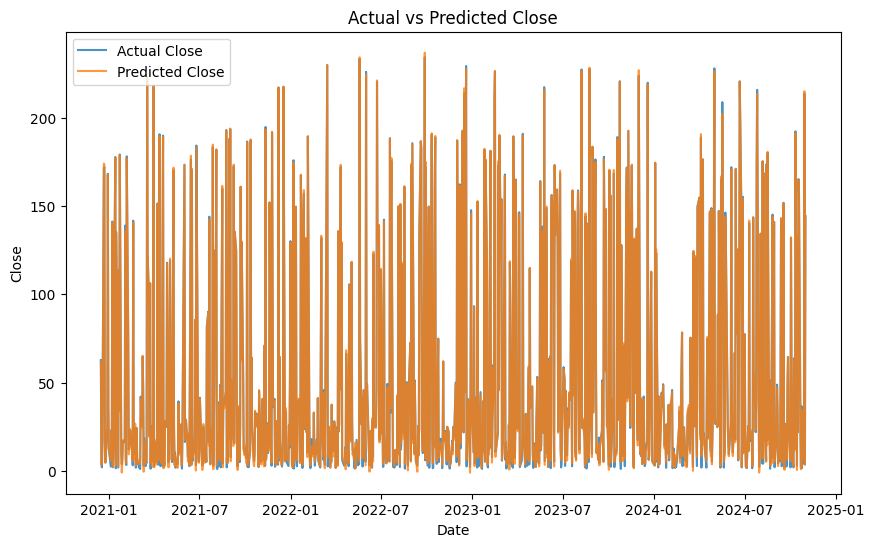

In [152]:
data = data.dropna()
target = 'Close'
features = [
    'Open', 'High', 'Low', 'Avg_Gain', 'Dividends', 'Stock Splits',
    'Quarter', 'week_number', 'week_day', 'month', 'Inflation', 'CPI',
    'Daily Range', 'Direction', 'Volume', 'Momentum_10', 'SMA_5', 'SMA_20',
    '5-Day Volatility', 'Change', 'Gain', 'Loss', 'Daily Return', 'Avg_Loss',
    'RS', 'RSI', 'Volume_SMA_10', 'Volume Change', 'OBV',
    'Percentage Change', '7-Day Return', '1-Month Return', '6-Month Return',
    '1-Year Return'
]


X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.1,
    objective='reg:squarederror',
    random_state=42,
    booster="gblinear"
)

# Train the model
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Plot predictions vs actuals
plt.figure(figsize=(10, 6))
plt.plot(data['Date'][-len(y_test):], y_test, label=f'Actual {target}', alpha=0.8)
plt.plot(data['Date'][-len(y_test):], y_pred, label=f'Predicted {target}', alpha=0.8)
plt.legend()
plt.title(f'Actual vs Predicted {target}')
plt.xlabel('Date')
plt.ylabel(target)
plt.show()
